# Lab 2 — What Did the Campaign Deliver?

Name: Anastasiia Movchaniuk | Group: КМ-43

## Setup

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

DATA = Path(kagglehub.dataset_download('shkarupylomaxim/adtech-lab1-tv-panel/versions/3'))
programs = pd.read_parquet(DATA / 'programs.parquet')
viewings = pd.read_parquet(DATA / 'viewings.parquet')
daily_weights = pd.read_parquet(DATA / 'daily_weights.parquet')
viewer_attributes = pd.read_parquet(DATA / 'viewer_attributes.parquet')
attributes = pd.read_parquet(DATA / 'attributes.parquet')
commercials = pd.read_parquet(DATA / 'commercials.parquet')
rate_card = pd.read_parquet(DATA / 'rate_card.parquet')

100%|██████████| 8.00M/8.00M [00:01<00:00, 5.97MB/s]

Extracting files...


## Task 1.1 — Size

In [2]:
spots = commercials.merge(programs[['telecast_id','program_name','broadcast_date']], on='telecast_id', validate='many_to_one')
spots['start_ts'] = pd.to_datetime(spots['start_ts'])
spots['broadcast_date'] = pd.to_datetime(spots['broadcast_date']).dt.normalize()
for label, column in [('Spots:', 'ad_airing_id'), ('Pods:', 'pod_id'), ('Brands:', 'brand'), ('Categories:', 'category')]:
    print(label, spots[column].nunique())
print('BRAND_A spots:', spots['brand'].eq('BRAND_A').sum())
display(spots[spots.brand.eq('BRAND_A')].groupby('network_code').size().to_frame('Spots'))

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300


,Spots
network_code,
ABC,29
BRAVO,33
CBS,22
FNC,40
FOOD,33
FOX,13
FX,38
HGTV,39
HIST,37


## Task 1.2 — Ad load

In [3]:
ad_load = spots.groupby(['network_code', spots.start_ts.dt.floor('h')]).length_sec.sum().groupby(level=0).mean() / 60
print('Heaviest ad load:', ad_load.idxmax())
display(ad_load.sort_values(ascending=False).round(2).to_frame('Ad minutes per active hour'))

Heaviest ad load: FNC


,Ad minutes per active hour
network_code,
FNC,15.64
BRAVO,13.43
HGTV,13.34
HIST,13.21
FOOD,13.11
FX,12.92
CBS,12.14
ABC,11.84
NBC,11.82


**Answer:** Local stations sell their own breaks during local programming blocks. The log records national spots, so those hours may contain no national ads.

## Task 1.3 — Price everything

In [4]:
program_rates = rate_card[rate_card.program_name.fillna('').str.strip().ne('')]
time_rates = rate_card.drop(program_rates.index)
rate_columns = ['daypart', 'cost_30s_usd']
spots = spots.merge(program_rates[['network_code','program_name', *rate_columns]], on=['network_code','program_name'], how='left', validate='many_to_one')
spots['program_price'] = spots.cost_30s_usd.notna()
clock = spots.start_ts - pd.Timedelta(hours=6)
minute = clock.dt.hour * 60 + clock.dt.minute

def broadcast_minutes(time):
    hours, minutes = map(int, time.split(':'))
    return hours * 60 + minutes - 360

for rate in time_rates.itertuples(index=False):
    matches = (spots.network_code.eq(rate.network_code) & ~spots.program_price
               & clock.dt.dayofweek.isin(rate.weekdays)
               & minute.ge(broadcast_minutes(rate.start_time))
               & minute.lt(broadcast_minutes(rate.end_time)))
    assert spots.loc[matches, 'cost_30s_usd'].isna().all(), 'Overlapping time prices'
    spots.loc[matches, 'daypart'] = rate.daypart
    spots.loc[matches, 'cost_30s_usd'] = rate.cost_30s_usd

spots['cost'] = spots.cost_30s_usd * spots.length_sec / 30
print('Spots without a price:', spots.cost.isna().sum())
assert spots.cost.notna().all()
price_summary = spots.groupby('network_code').cost.sum().to_frame('Total cost')
program_cost = spots[spots.program_price].groupby('network_code').cost.sum()
price_summary['Program share'] = program_cost.reindex(price_summary.index, fill_value=0) / price_summary['Total cost']
price_summary['Rate-card value (USD M)'] = price_summary.pop('Total cost') / 1e6
display(price_summary.style.format('{:.3f}'))

Spots without a price: 0


,Program share,Rate-card value (USD M)
network_code,,
ABC,0.432,708.787
BRAVO,0.000,25.313
CBS,0.230,818.778
FNC,0.000,315.845
FOOD,0.000,42.149
FOX,0.835,696.173
FX,0.000,42.506
HGTV,0.000,58.103
HIST,0.000,40.085


## Task 2.1 — Delivery

In [5]:
campaign = spots.loc[spots.brand.eq('BRAND_A')].copy()
people = daily_weights.loc[daily_weights.resp_type.isin(['R','L'])].copy()
people['broadcast_date'] = pd.to_datetime(people.broadcast_date).dt.normalize()
monthly = people.groupby('respondent_id').weight.mean()
age = viewer_attributes.loc[viewer_attributes.attr_id.eq(300)].set_index('respondent_id').value
female = viewer_attributes.loc[viewer_attributes.attr_id.eq(202), 'respondent_id']
target = age.index[age.between(18,49)]
w1834 = age.index[age.between(18,34)].intersection(female)
people['target_weight'] = people.weight.where(people.respondent_id.isin(target), 0)
by_day = people.groupby('broadcast_date').agg(universe=('weight','sum'), target_universe=('target_weight','sum'), n=('respondent_id','size'))
sessions = viewings.loc[viewings.resp_type.isin(['R','L']), ['respondent_id','network_code','start_ts','end_ts']].copy()
for col in ['start_ts','end_ts']:
    sessions[col] = pd.to_datetime(sessions[col])
network_sessions = dict(tuple(sessions.groupby('network_code')))
exposure_parts = []
for spot in campaign.itertuples(index=False):
    net = network_sessions[spot.network_code]
    ids = net.loc[net.start_ts.le(spot.start_ts) & net.end_ts.gt(spot.start_ts), 'respondent_id'].unique()
    day = people.loc[people.broadcast_date.eq(spot.broadcast_date) & people.respondent_id.isin(ids), ['respondent_id','weight','target_weight']]
    exposure_parts.append(day.assign(ad_airing_id=spot.ad_airing_id, network_code=spot.network_code))
exposures = pd.concat(exposure_parts, ignore_index=True)
exposures['w1834'] = exposures.respondent_id.isin(w1834)
spot_metrics = exposures.groupby('ad_airing_id').agg(impressions=('weight','sum'), target_impressions=('target_weight','sum'), panelists=('respondent_id','size'), w1834=('w1834','sum'))
campaign = campaign.join(spot_metrics, on='ad_airing_id').join(by_day, on='broadcast_date')
for col in spot_metrics.columns:
    campaign[col] = campaign[col].fillna(0)
campaign['rating'] = 100 * campaign.impressions / campaign.universe
campaign['target_rating'] = 100 * campaign.target_impressions / campaign.target_universe

def reach_percent(ids, universe):
    return 100 * universe.loc[universe.index.isin(ids)].sum() / universe.sum()

target_monthly = monthly.loc[monthly.index.isin(target)]
reached = set(exposures.respondent_id)
p2_reach = reach_percent(reached, monthly)
target_reach = reach_percent(reached, target_monthly)
p2_grp = campaign.rating.sum()
target_grp = campaign.target_rating.sum()
p2_imp = campaign.impressions.sum()
target_imp = campaign.target_impressions.sum()
for name, imp, grp, reach in [('P2+', p2_imp, p2_grp, p2_reach), ('A18-49', target_imp, target_grp, target_reach)]:
    print(f'{name} impressions (M):', f'{imp / 1e6:.1f}')
    print(f'{name} GRPs:', f'{grp:.1f}')
    print(f'{name} reach (%):', f'{reach:.1f}')
    print(f'{name} average frequency:', f'{grp / reach:.1f}')

P2+ impressions (M): 418.8
P2+ GRPs: 132.0
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.1
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


## Task 2.2 — Frequency distribution

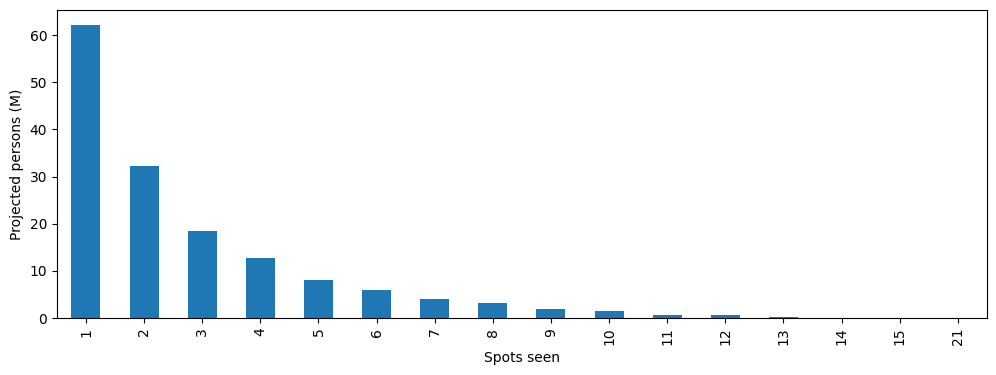

Share of impressions at 5+ exposures: 0.444


In [6]:
counts = exposures.groupby('respondent_id').size()
frequency = counts.rename('spots_seen').to_frame().join(monthly.rename('monthly_weight'))
frequency.groupby('spots_seen').monthly_weight.sum().div(1e6).plot.bar(figsize=(12,4), xlabel='Spots seen', ylabel='Projected persons (M)')
plt.show()
share5 = exposures.loc[exposures.respondent_id.isin(counts.index[counts.ge(5)]), 'weight'].sum() / p2_imp
print('Share of impressions at 5+ exposures:', f'{share5:.3f}')
freq_bins = frequency.groupby('spots_seen').monthly_weight.sum()
median_freq = freq_bins.index[freq_bins.cumsum().ge(freq_bins.sum() / 2)][0]

**Answer:** The weighted median was 2 exposures, and viewers with five or more exposures generated 44.4% of impressions. Average frequency alone hides how concentrated repeat exposure was.

## Task 2.3 — On target?

In [7]:
print('Share of impressions on A18-49:', f'{target_imp / p2_imp:.3f}')
network = campaign.groupby('network_code').agg(spots=('ad_airing_id','size'), cost=('cost','sum'), impressions=('impressions','sum'), target_impressions=('target_impressions','sum'))
network['Target share'] = network.target_impressions / network.impressions
network['Target surplus vs 42% (M)'] = (network.target_impressions - .42 * network.impressions) / 1e6
display(network[['Target share','Target surplus vs 42% (M)']].round(3))
direction = 'overdelivered' if target_imp / p2_imp >= .42 else 'underdelivered'
leading = network['Target surplus vs 42% (M)'].abs().nlargest(3).index

Share of impressions on A18-49: 0.194


,Target share,Target surplus vs 42% (M)
network_code,,
ABC,0.180,-22.580
BRAVO,0.554,0.682
CBS,0.154,-23.678
FNC,0.047,-21.558
FOOD,0.316,-0.990
FOX,0.242,-13.587
FX,0.651,1.972
HGTV,0.306,-2.802
HIST,0.202,-2.694


**Answer:** Adults aged 18–49 received 19.4% of impressions against a 42% population benchmark, so the campaign underdelivered on its target. CBS, ABC and FNC contributed the largest absolute gaps.

## Task 3.1 — Cost

In [8]:
campaign_cost = campaign.cost.sum()
p2_cpp = campaign_cost / p2_grp
print('Campaign cost (USD):', f'{campaign_cost:.0f}')
print('P2+ CPM (USD):', f'{1000 * campaign_cost / p2_imp:.2f}')
print('P2+ CPP (USD):', f'{p2_cpp:.0f}')
print('A18-49 CPM (USD):', f'{1000 * campaign_cost / target_imp:.2f}')
print('A18-49 CPP (USD):', f'{campaign_cost / target_grp:.0f}')

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.72
P2+ CPP (USD): 56221
A18-49 CPM (USD): 91.53
A18-49 CPP (USD): 122836


## Task 3.2 — By network

In [9]:
network['P2+ CPM'] = 1000 * network.cost / network.impressions
network['A18-49 CPM'] = 1000 * network.cost / network.target_impressions
by_network = network.assign(impressions=network.impressions / 1e6, target_impressions=network.target_impressions / 1e6)
display(by_network[['spots','cost','impressions','target_impressions','P2+ CPM','A18-49 CPM']].sort_values('cost', ascending=False).style.format({'cost':'{:.0f}','impressions':'{:.1f}','target_impressions':'{:.1f}','P2+ CPM':'{:.2f}','A18-49 CPM':'{:.2f}'}))

,spots,cost,impressions,target_impressions,P2+ CPM,A18-49 CPM
network_code,,,,,,
FOX,13,2434700,76.3,18.4,31.93,132.03
ABC,29,1625700,94.2,17.0,17.26,95.69
CBS,22,1488700,89.0,13.7,16.73,108.72
NBC,16,796800,41.4,7.8,19.23,101.72
FNC,40,526300,57.8,2.7,9.11,193.70
HGTV,39,230000,24.7,7.6,9.33,30.45
FOOD,33,96620,9.5,3.0,10.19,32.29
FX,38,92200,8.5,5.6,10.82,16.61
HIST,37,79640,12.3,2.5,6.46,32.05


**Answer:** FOX received the most spend. FX offered the lowest cost per thousand A18–49 impressions, at $16.61.

## Task 3.3 — Guarantee

In [10]:
owed = max(0, 150 - p2_grp)
print('Guarantee met:', p2_grp >= 150)
print('Make-good GRPs owed:', f'{owed:.1f}')
print('Value of make-goods (USD):', f'{owed * p2_cpp:.0f}')

Guarantee met: False
Make-good GRPs owed: 18.0
Value of make-goods (USD): 1012869


## Task 4 — Do networks add up?

In [11]:
big = ['CBS','NBC','ABC','FOX','FNC']
exp_big = exposures.network_code.isin(big)
big_ids = set(exposures.loc[exp_big, 'respondent_id'])
small_ids = set(exposures.loc[~exp_big, 'respondent_id'])
big_reach = reach_percent(big_ids, monthly)
small_reach = reach_percent(small_ids, monthly)
overlap = reach_percent(big_ids & small_ids, monthly)
independent = big_reach * small_reach / 100
added = p2_reach - big_reach
big_cost = campaign.loc[campaign.network_code.isin(big), 'cost'].sum()
small_cost = campaign_cost - big_cost
for label, value in [('Reach, big networks (%):', big_reach), ('Reach, small networks (%):', small_reach), ('Reach, whole campaign (%):', p2_reach), ('Overlap (%):', overlap), ('Overlap if independent (%):', independent), ('Reach added by small networks (points):', added)]:
    print(label, f'{value:.1f}')
print('Cost per added reach point, small (USD):', f'{small_cost / added:.0f}')
print('Cost per reach point, big (USD):', f'{big_cost / big_reach:.0f}')

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148706
Cost per reach point, big (USD): 172456


**Answer:** Some people saw spots on both network groups, so adding their reaches would count those people twice. The observed overlap was higher than under independence, consistent with shared viewing habits. Small networks added 3.7 reach points at a lower cost per point than the big-network average.

## Task 5 — How sure are we?

In [12]:
p = campaign.rating / 100
campaign['SE'] = 100 * np.sqrt(p * (1 - p) / campaign.n)
# Relative SE is undefined at zero rating. Count zero spots separately.
campaign['relative_se'] = campaign.SE / campaign.rating.replace(0, np.nan)
campaign['big_network'] = campaign.network_code.isin(big)
display(campaign.groupby('network_code')[['panelists','relative_se']].median().round(3))
print('Spots seen by no panelist:', campaign.panelists.eq(0).sum())
print('Median relative SE, big networks:', f'{campaign.loc[campaign.big_network, "relative_se"].median():.3f}')
print('Median relative SE, small networks:', f'{campaign.loc[~campaign.big_network, "relative_se"].median():.3f}')
print('W18-34 zero-cell spots:', campaign.w1834.eq(0).sum())

,panelists,relative_se
network_code,,
ABC,57.0,0.123
BRAVO,3.0,0.540
CBS,69.0,0.113
FNC,31.0,0.164
FOOD,5.0,0.423
FOX,145.0,0.080
FX,5.5,0.423
HGTV,11.0,0.301
HIST,5.0,0.460


Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** A zero panel count produces a zero measured rating, even if the true audience is positive. With 171 W18–34 zero cells, I would pool spots and show panel counts alongside the estimates. The simple random sample standard error is a lower bound for a weighted panel.

## Bonus

In [13]:
# Compare the target CPM of the observed FOX buy with FX inventory by daypart.
fx_inventory = campaign.loc[campaign.network_code.eq('FX')].groupby('daypart').agg(spots=('ad_airing_id', 'size'), cost=('cost', 'sum'), target_impressions=('target_impressions','sum'))
fx_inventory = fx_inventory.loc[fx_inventory.target_impressions.gt(0)].copy()
fx_inventory['target_cpm'] = 1000 * fx_inventory.cost / fx_inventory.target_impressions
fx_choice = fx_inventory.loc[fx_inventory.target_cpm.idxmin()]
fox_spots = campaign.loc[campaign.network_code.isin(big)].nlargest(20, 'cost')
budget = fox_spots.cost.sum()
fox_impressions = fox_spots.target_impressions.sum()
fx_estimate = budget / fx_choice.target_cpm * 1000
display(fx_inventory.round(2))

,spots,cost,target_impressions,target_cpm
daypart,,,,
Daytime Movies,25,27500.0,2311756.0,11.90
Fringe,5,14500.0,724736.0,20.01
Late Night,2,2200.0,171468.0,12.83
Prime,6,48000.0,2343170.0,20.49


**Answer:** I would test shifting some budget from the 20 most expensive big-network spots to FX Daytime Movies, where the observed target CPM was USD 11.90. Those 20 spots cost USD 4,065,800 and delivered 29.0 million target impressions. Their observed target CPM was about USD 140.20, so a shift could lower the campaign’s target CPM if comparable FX inventory is available.